# AF8: Redes Neuronales Convolucionales

Hora: N1-N3



*   Reynaldo Aldape Sonora 2028750
*   Sergio Daniel Suárez Aguirre 2127902
*   Angel Esteban Pedraza Gomez 2097528
*   Emilio David Cerda Salazar 2070100

In [ ]:
#Cargar librerias (Keras y TensorFlow)

### 📚 Explicación: Importar librerías

Se cargan las herramientas para construir y probar la red neuronal convolucional:

- `tensorflow as tf`: framework principal de aprendizaje automático.
- `keras`: interfaz de alto nivel para construir redes neuronales de forma sencilla.
- `datasets, layers, models`: de Keras, se usan `datasets` para obtener MNIST, `layers` para las capas de la red y `models` para armar el modelo.
- `matplotlib.pyplot as plt`: para mostrar las imágenes de prueba con su predicción.
- `numpy as np`: manejo de arreglos; aquí sirve para obtener la clase predicha con `argmax`.

Esta celda no imprime nada; solo deja todo listo.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
#Cargar datos

### 📚 Explicación: Cargar los datos (MNIST)

`datasets.mnist.load_data()` descarga el dataset de dígitos escritos a mano (solo la primera vez) y lo entrega ya dividido en dos grupos:

- **Entrenamiento:** `train_data` (imágenes) y `train_labels` (el dígito correcto de cada una).
- **Prueba:** `test_data` y `test_label`, imágenes que el modelo **no verá durante el entrenamiento**.

Los dos `print` con `.shape` sirven para confirmar las dimensiones de los datos.

**Resultados obtenidos:**
- `train_data`: `(60000, 28, 28)`, es decir, 60,000 imágenes de 28×28 píxeles en escala de grises.
- `test_data`: `(10000, 28, 28)`, o sea, 10,000 imágenes para la prueba final.
- El mensaje `Downloading data from ...mnist.npz` solo indica que se descargó el archivo del dataset.

In [ ]:
(train_data, train_labels), (test_data, test_label) = datasets.mnist.load_data()

print("Forma de los datos de entrenamiento (train_data):", train_data.shape)
print("Forma de los datos de prueba (test_data):", test_data.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Forma de los datos de entrenamiento (train_data): (60000, 28, 28)
Forma de los datos de prueba (test_data): (10000, 28, 28)


In [ ]:
#Reprocesamiento de datos (Normalización)

### 📚 Explicación: Preprocesamiento (normalización)

`train_data / 255.0` y `test_data / 255.0` dividen cada píxel entre 255, con lo que sus valores pasan del rango 0–255 al rango **0–1**.

Esto es necesario porque las redes neuronales aprenden más rápido y de forma más estable con entradas pequeñas y en una escala uniforme. Se aplica la **misma transformación** a entrenamiento y a prueba para que el modelo vea datos con la misma escala en ambas etapas.

Esta celda no imprime nada.

In [ ]:
train_data = train_data / 255.0
test_data = test_data / 255.0

### 📚 Explicación: Agregar el canal de color

Las capas convolucionales (`Conv2D`) esperan imágenes con forma `(alto, ancho, canales)`. Como MNIST es en escala de grises, las imágenes llegan como `(28, 28)` sin la dimensión de canales. Con `[..., tf.newaxis]` se agrega esa dimensión al final: un solo canal (gris), a diferencia de las imágenes a color, que tendrían 3 (rojo, verde y azul).

**Resultado esperado:** `(60000, 28, 28, 1)`, es decir, 60,000 imágenes de 28×28 píxeles con 1 canal.

**⚠️ Resultado obtenido:** la salida muestra `(60000, 28, 28, 1, 1)`, con un `1` de más. Eso pasa cuando esta celda se ejecuta **dos veces seguidas**: cada ejecución vuelve a agregar un eje nuevo sobre los datos que ya lo tenían. En una ejecución limpia, la forma correcta es `(60000, 28, 28, 1)`. Para evitarlo, usa *Entorno de ejecución → Reiniciar y ejecutar todo* y corre esta celda una sola vez.

In [ ]:
train_data = train_data[..., tf.newaxis]
test_data = test_data[..., tf.newaxis]

print("Forma de train_data tras el preprocesamiento:", train_data.shape)

Forma de train_data tras el preprocesamiento: (60000, 28, 28, 1, 1)


In [ ]:
#Selección y entrenamiento del modelo

### 📚 Explicación: Definir, compilar y entrenar la CNN

**1. Arquitectura (`Sequential`)**: las capas se apilan en orden.
- `Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1))`: 32 filtros de 3×3 que recorren la imagen y detectan patrones simples (bordes, líneas, curvas). ReLU deja pasar los valores positivos y convierte los negativos en 0.
- `MaxPooling2D((2, 2))`: reduce a la mitad el tamaño del mapa de características, quedándose con el valor máximo de cada bloque de 2×2. Así se conserva lo más importante y se reducen los cálculos.
- `Conv2D(64, (3, 3), activation='relu')`: 64 filtros que combinan los patrones simples en formas más complejas.
- `MaxPooling2D((2, 2))`: segunda reducción de tamaño.
- `Flatten()`: convierte los mapas de características en un único vector de 1600 valores.
- `Dense(64, activation='relu')`: capa totalmente conectada de 64 neuronas que interpreta esos patrones.
- `Dense(10, activation='softmax')`: capa de salida con 10 neuronas, una por dígito. Softmax las convierte en probabilidades que suman 1.

**2. Compilación (`compile`)**
- `optimizer='adam'`: algoritmo que ajusta los pesos y adapta su velocidad de aprendizaje.
- `loss='sparse_categorical_crossentropy'`: pérdida para clasificación de varias clases con etiquetas enteras (0–9).
- `metrics=['accuracy']`: porcentaje de aciertos que se reporta en cada época.

**3. Entrenamiento (`fit`)**
- `model.summary()` imprime la estructura de la red.
- `EPOCHS = 10`: la red recorre los datos 10 veces.
- `validation_split=0.1`: separa el 10 % de los datos de entrenamiento (6,000 imágenes) para **validar** en cada época. Por eso se entrena con 54,000 y cada época tiene 1688 pasos (54,000 / 32, redondeado hacia arriba).

**Resultados obtenidos:**
- **Resumen del modelo:** forma de salida y parámetros por capa:

| Capa | Forma de salida | Parámetros |
|---|---|---|
| Conv2D (32 filtros) | 26×26×32 | 320 |
| MaxPooling2D | 13×13×32 | 0 |
| Conv2D (64 filtros) | 11×11×64 | 18,496 |
| MaxPooling2D | 5×5×64 | 0 |
| Flatten | 1600 | 0 |
| Dense (64) | 64 | 102,464 |
| Dense (10) | 10 | 650 |

  En total son **121,930 parámetros entrenables**. Casi todos están en la primera capa `Dense`, porque recibe los 1600 valores aplanados.
- **Entrenamiento:** la precisión de entrenamiento pasó de **0.9535** (época 1) a **0.9977** (época 10), y la pérdida bajó de 0.1551 a 0.0064.
- **Validación:** la precisión de validación subió de 0.9832 a un máximo de **0.9912** en la época 8, y terminó en 0.9885.
- **Posible sobreajuste:** después de la época 7, la pérdida de validación deja de bajar y sube (de 0.0378 a 0.0566) mientras la de entrenamiento sigue bajando. El modelo empieza a memorizar los datos de entrenamiento; 10 épocas funcionan bien, pero entrenar más no ayudaría.
- El `UserWarning` sobre `input_shape` no es un error: Keras sugiere declarar la entrada con un objeto `Input(shape)` en lugar de pasarla a la primera capa, pero el modelo funciona igual.

In [ ]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

EPOCHS = 10
history = model.fit(train_data, train_labels, epochs=EPOCHS, validation_split=0.1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 49s 28ms/step - accuracy: 0.9535 - loss: 0.1551 - val_accuracy: 0.9832 - val_loss: 0.0563
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 46s 27ms/step - accuracy: 0.9840 - loss: 0.0512 - val_accuracy: 0.9848 - val_loss: 0.0511
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 47s 28ms/step - accuracy: 0.9893 - loss: 0.0346 - val_accuracy: 0.9880 - val_loss: 0.0441
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 80s 27ms/step - accuracy: 0.9914 - loss: 0.0259 - val_accuracy: 0.9882 - val_loss: 0.0425
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 82s 27ms/step - accuracy: 0.9935 - loss: 0.0194 - val_accuracy: 0.9890 - val_loss: 0.0420
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 81s 26ms/step - accuracy: 0.9950 - loss: 0.0152 - val_accuracy: 0.9908 - val_loss: 0.0389
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 44s 26ms/step - accuracy: 0.9957 - loss: 0.0119 - val_accuracy: 0.9908 - val_loss: 0.0378
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 84s 27ms/step - accuracy: 0.9965 -

In [ ]:
#Prueba del modelo e imagenes

### 📚 Explicación: Evaluación del modelo y prueba con imágenes

**1. Evaluación general**
- `model.evaluate(test_data, test_label)` mide la pérdida y la exactitud del modelo sobre las 10,000 imágenes de **prueba**, que nunca se usaron para entrenar. Con `verbose=2` imprime una sola línea de resumen.
- El `print` con `test_acc * 100:.2f` muestra la exactitud como porcentaje con 2 decimales.

**2. Predicciones individuales**
- `model.predict(test_data[:5])` obtiene, para las primeras 5 imágenes de prueba, las 10 probabilidades (una por dígito).
- En el ciclo `for`, `np.argmax(predictions[i])` toma la posición de la probabilidad más alta, que es el dígito que predice el modelo, y se compara con `test_label[i]`, el valor real.

**3. Gráfica**
- `plt.figure(figsize=(10, 3))` y `plt.subplot(1, 5, i + 1)` arman una fila con 5 imágenes.
- `test_data[i].squeeze()` quita la dimensión del canal para que `imshow` pueda mostrar la imagen en escala de grises (`cmap='gray'`).
- El título de cada imagen muestra la predicción y el valor real, y `plt.axis('off')` oculta los ejes.

**Resultados obtenidos:**
- **Exactitud en el conjunto de prueba: 98.98 %** (pérdida de 0.0383). Es consistente con la precisión de validación y confirma que el modelo generaliza bien a imágenes nuevas.
- **Predicciones:**

| # | Predicho | Real | Resultado |
|---|---|---|---|
| 1 | 7 | 7 | ✅ |
| 2 | 2 | 2 | ✅ |
| 3 | 1 | 1 | ✅ |
| 4 | 0 | 0 | ✅ |
| 5 | 4 | 4 | ✅ |

El modelo acertó las 5 de 5. Son solo 5 ejemplos, así que la medida confiable del desempeño es el 98.98 % calculado sobre las 10,000 imágenes.

313/313 - 3s - 9ms/step - accuracy: 0.9898 - loss: 0.0383

Exactitud (Accuracy) en el conjunto de prueba: 98.98%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step

--- 5 PREDICCIONES DE PRUEBA ---
Predicción 1: El modelo predice el dígito [7] | El valor real es [7]
Predicción 2: El modelo predice el dígito [2] | El valor real es [2]
Predicción 3: El modelo predice el dígito [1] | El valor real es [1]
Predicción 4: El modelo predice el dígito [0] | El valor real es [0]
Predicción 5: El modelo predice el dígito [4] | El valor real es [4]


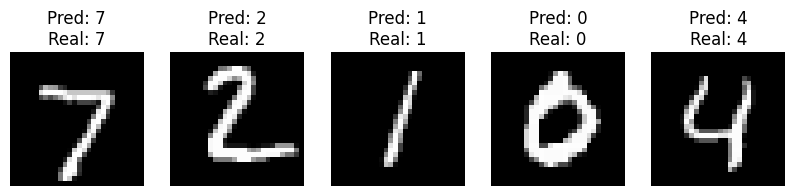

In [ ]:
test_loss, test_acc = model.evaluate(test_data, test_label, verbose=2)
print(f"\nExactitud (Accuracy) en el conjunto de prueba: {test_acc * 100:.2f}%")

predictions = model.predict(test_data[:5])

print("\n--- 5 PREDICCIONES DE PRUEBA ---")
for i in range(5):
    predicted_label = np.argmax(predictions[i])
    real_label = test_label[i]
    print(f"Predicción {i+1}: El modelo predice el dígito [{predicted_label}] | El valor real es [{real_label}]")

plt.figure(figsize=(10, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_data[i].squeeze(), cmap='gray')
    plt.title(f"Pred: {np.argmax(predictions[i])}\nReal: {test_label[i]}")
    plt.axis('off')
plt.show()